# 01 · Images are numbers: your first CNN

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/maryammahmoudi1993/FashionNet/blob/main/notebooks/01_images_as_numbers_and_first_cnn.ipynb)

**After this notebook you will be able to** explain how a computer "sees" a picture, what a
convolution does, and train a small convolutional neural network (CNN) that recognises ten kinds of clothes.

*Time: about 25 minutes (the training cells take roughly one minute on a laptop CPU). No GPU needed.
Prior knowledge: basic Python and NumPy; you do not need to know any deep learning.*

## 1 · The big question

A shop wants to sort photos of clothes automatically: *this one is a sneaker, that one is a coat*.
You can tell at a glance. A computer cannot: for it, a photo is only a table of numbers.

**How can a program turn a table of numbers into the word "sneaker"?**
That is the question of this whole repository. Today we build the simplest honest answer.

*Data we use:* **Fashion-MNIST**, 70,000 small grey pictures of clothes in 10 classes
(see [`data/README.md`](../data/README.md) for the licence and the citation).
Later notebooks will go further; the first version of this project, from 2023, is kept in [`legacy/`](../legacy/).

## 2 · Intuition first: a picture is a spreadsheet

Imagine a mosaic made of tiny square tiles. Each tile has exactly one shade, from white to black.
If you write down the shade of every tile, row after row, you have a spreadsheet, and the spreadsheet
holds *all* the information in the picture.

That is exactly how our pictures are stored: **28 rows × 28 columns of tiles ("pixels"), each with
a number between 0 (white) and 255 (black)**. We divide by 255 so that every number sits between 0 and 1,
which makes training easier.

> **Predict before you look:** how many numbers describe one picture?

In [1]:
import os, pathlib, subprocess, sys

# On Google Colab the repository is not there yet, so we download it once.
if "google.colab" in sys.modules and not pathlib.Path("src").exists():
    subprocess.run(["git", "clone", "--depth", "1",
                    "https://github.com/maryammahmoudi1993/FashionNet.git"], check=True)
    os.chdir("FashionNet/notebooks")

sys.path.insert(0, str(pathlib.Path.cwd().resolve().parent))   # lets us import from src/

import numpy as np
import matplotlib.pyplot as plt

from src import fashion
from src.fashion import CLASS_NAMES, save_figure

fashion.set_seed()                 # fixed seed (42): you should get the same numbers as the author
plt.rcParams["figure.dpi"] = 100

In [2]:
(x_train, y_train), (x_val, y_val), (x_test, y_test) = fashion.load_fashion(n_train=20000, n_val=5000)

print("training pictures  :", x_train.shape)
print("validation pictures:", x_val.shape)
print("test pictures      :", x_test.shape)
print("smallest and largest pixel value:", x_train.min(), x_train.max())
print("numbers per picture:", 28 * 28)

training pictures  : (20000, 28, 28, 1)
validation pictures: (5000, 28, 28, 1)
test pictures      : (10000, 28, 28, 1)
smallest and largest pixel value: 0.0 1.0
numbers per picture: 784


**What to notice.** The shape `(20000, 28, 28, 1)` reads: 20,000 pictures, 28 rows, 28 columns, 1 channel
(grey; a colour photo would have 3 channels: red, green, blue). So one picture is 28 × 28 = **784 numbers**.

We split the data into three parts and each has one job:

- **training** pictures: the network learns from them;
- **validation** pictures: we watch them during training to see whether the network really learns or only memorises;
- **test** pictures: locked away until the very end, used once for the final grade.

To keep the notebook fast we use a random 20,000 of the 60,000 training pictures (the choice is fixed by the seed).

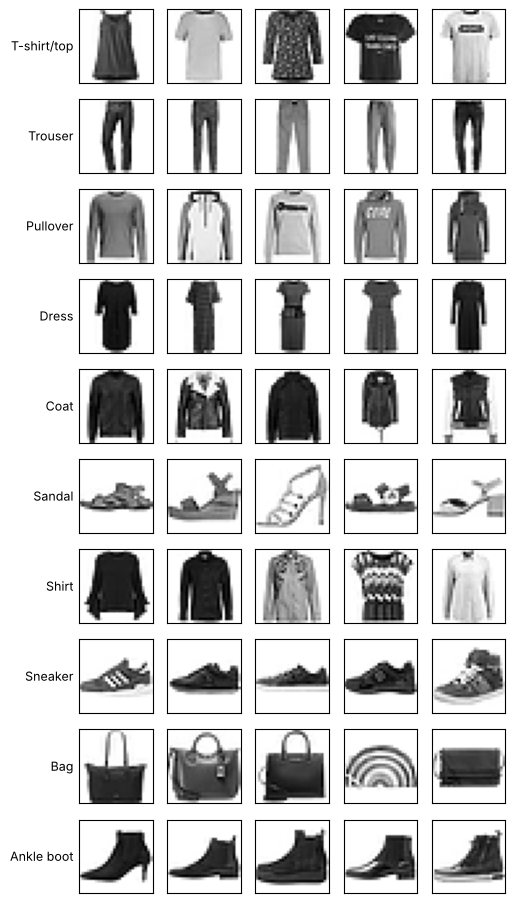

In [3]:
fig = fashion.plot_class_grid(x_train, y_train, per_class=5)
save_figure(fig, "01_classes.png")
plt.show()

**What to notice.** Ten classes, five examples each. Some are easy to tell apart (a trouser and a bag), some are
easy to confuse even for you (T-shirt, shirt, pullover and coat look alike at 28 × 28 pixels). Keep this in mind: later,
the network's mistakes will land in exactly these pairs.

*Figure: five random training examples of each of the ten classes. Look at the "shirt" row and compare it with "T-shirt/top".*

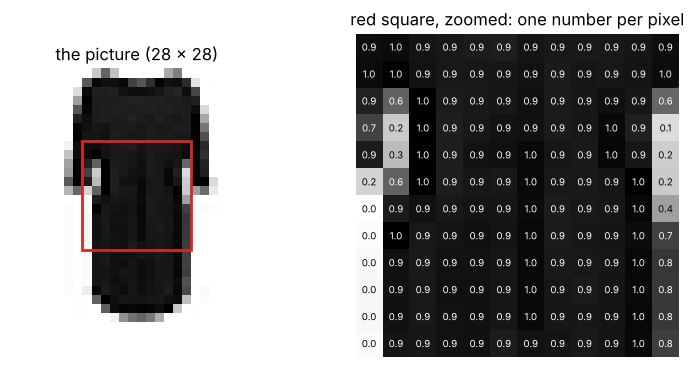

this picture is a: Dress


In [4]:
fig = fashion.plot_pixels(x_train[0, :, :, 0])
save_figure(fig, "01_pixels.png")
plt.show()
print("this picture is a:", CLASS_NAMES[y_train[0]])

**What to notice.** On the right, the red square is shown as numbers. Where the cloth is, the numbers are close to 1
(dark); in the empty background they are 0. There is no "shirt" or "sneaker" anywhere in these numbers: the network
has to discover the pattern by itself.

*Figure: a training picture and a zoom on 12 × 12 of its pixels with the value printed in every pixel.*

### Check yourself

1. A colour photo is 100 × 100 pixels. How many numbers describe it?
2. Why do we keep a test set that is never used during training?

<details>
<summary>Answers</summary>


1. 100 × 100 × 3 = **30,000** numbers (3 channels: red, green and blue).
2. If we tuned the model on the test pictures we would be grading it on questions it has already seen.
   The test score would then be too optimistic. A locked test set gives one honest number at the end.

</details>

## 3 · A first attempt without convolution: the "flat list" network

The simplest network ignores the picture shape: it lays the 784 numbers in one long line and mixes them
with a hidden layer of 64 units. Think of someone who receives the *cut-up strips* of a photo and has to guess the
content without knowing which strip was next to which.

*In maths:* each hidden unit computes $h = \max(0,\, w_1 p_1 + w_2 p_2 + \dots + w_{784} p_{784} + b)$, where
$p_i$ is the value of pixel $i$, $w_i$ is a weight the network learns, $b$ is a learned offset, and $\max(0,\cdot)$
("ReLU") simply replaces negative numbers by 0. A final layer turns the 64 hidden numbers into
10 probabilities, one per class (the "softmax" makes them sum to 1).

> **Predict:** if we scramble the pixel positions in the *same* random way in every picture, so the picture
> becomes unreadable for a human, will this network do much worse?

In [5]:
EPOCHS = 10          # one epoch = the network sees every training picture once

fashion.set_seed()
dense = fashion.compile_model(fashion.build_dense())
dense_history = dense.fit(x_train, y_train, epochs=EPOCHS, batch_size=64,
                          validation_data=(x_val, y_val), verbose=0).history
print("parameters (numbers the network learns):", dense.count_params())
print("validation accuracy per epoch:", [round(a, 3) for a in dense_history["val_accuracy"]])

parameters (numbers the network learns): 50890
validation accuracy per epoch: [0.831, 0.848, 0.858, 0.863, 0.862, 0.863, 0.862, 0.862, 0.86, 0.862]


**What to notice.** The network learns quickly and reaches a good validation accuracy within a few epochs, then it
stops improving (the later epochs hardly change). Accuracy is the share of pictures classified correctly.
Now the scrambling experiment:

validation accuracy, normal pictures   : 0.862
validation accuracy, scrambled pictures: 0.864


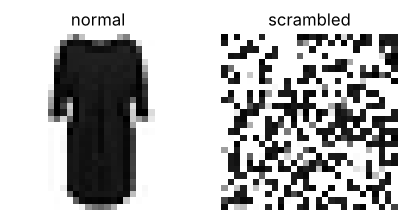

In [6]:
rng = np.random.default_rng(0)
order = rng.permutation(28 * 28)                       # one fixed scrambling of the 784 positions

def scramble(x):
    return x.reshape(len(x), -1)[:, order].reshape(x.shape)

fashion.set_seed()
dense_scrambled = fashion.compile_model(fashion.build_dense())
scrambled_history = dense_scrambled.fit(scramble(x_train), y_train, epochs=EPOCHS, batch_size=64,
                                        validation_data=(scramble(x_val), y_val), verbose=0).history
print("validation accuracy, normal pictures   :", round(dense_history["val_accuracy"][-1], 3))
print("validation accuracy, scrambled pictures:", round(scrambled_history["val_accuracy"][-1], 3))

fig, axes = plt.subplots(1, 2, figsize=(5, 2.6))
axes[0].imshow(x_train[0, :, :, 0], cmap="gray_r"); axes[0].set_title("normal"); axes[0].axis("off")
axes[1].imshow(scramble(x_train[:1])[0, :, :, 0], cmap="gray_r"); axes[1].set_title("scrambled"); axes[1].axis("off")
save_figure(fig, "01_scrambled.png")
plt.show()

**What to notice.** The scrambled picture is hopeless for a human, yet the flat-list network scores about the same.
That tells us something important: **this network never used the fact that pixels have neighbours**. It treats the picture
as 784 unrelated numbers. Yet a sleeve is a *group of neighbouring pixels*, and an edge is a place where neighbours differ.
A better network should use this structure. That is the job of convolution.

*Figure: the same training picture before and after the fixed scrambling of pixel positions.*

## 4 · Intuition: a convolution is a small magnifying window

Slide a tiny window (here 3 × 3 pixels) over the picture. At every position, ask one question about the nine pixels
inside, for example *"is there a vertical edge here, small numbers on the left and large numbers on the right?"* The answers,
one per position, form a new, slightly smaller picture called a **feature map**.
It lights up wherever the pattern exists.

**Math (light).** The window carries nine numbers, the *kernel* $K$. At each position we multiply the nine pixels $P$
under the window by the nine kernel numbers and add everything up:

$$\text{output} = \sum_{i=1}^{3}\sum_{j=1}^{3} P_{ij}\,K_{ij}$$

where $P_{ij}$ is the pixel in row $i$, column $j$ of the window and $K_{ij}$ is the kernel number at the same place.
A kernel with `-1` on the left, `0` in the middle and `+1` on the right gives a large positive result exactly
when the pixel values on the right are larger than on the left (in our pictures a larger value means a darker pixel).

A real CNN does not get its kernels from us: it **learns** them. Here we write two by hand to see what one can do.

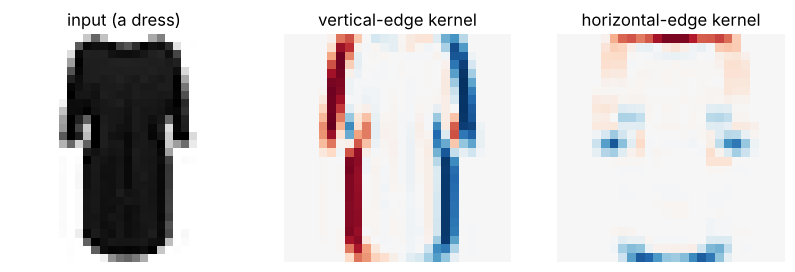

feature map size: (26, 26) (28 - 3 + 1 = 26 in each direction)


In [7]:
vertical_edge = np.array([[-1, 0, 1],
                          [-1, 0, 1],
                          [-1, 0, 1]], dtype="float32")
horizontal_edge = vertical_edge.T                      # the same idea, turned by 90 degrees

image = x_train[:, :, :, 0][np.flatnonzero(y_train == 3)[0]]    # a dress
maps = {"vertical-edge kernel": fashion.convolve2d(image, vertical_edge),
        "horizontal-edge kernel": fashion.convolve2d(image, horizontal_edge)}

fig, axes = plt.subplots(1, 3, figsize=(10, 3.4))
axes[0].imshow(image, cmap="gray_r"); axes[0].set_title("input (a dress)")
for ax, (name, m) in zip(axes[1:], maps.items()):
    ax.imshow(m, cmap="RdBu_r", vmin=-3, vmax=3); ax.set_title(name)
for ax in axes: ax.axis("off")
save_figure(fig, "01_edge_filters.png")
plt.show()
print("feature map size:", maps["vertical-edge kernel"].shape, "(28 - 3 + 1 = 26 in each direction)")

**What to notice.** In the middle panel, red marks places where the pixels get darker towards the right and blue
where they get lighter; the sides of the dress show up. In the right panel the horizontal edges (shoulders, hem) show up instead.
Each kernel answers one question. A CNN uses *many* kernels at once and learns which questions are useful.

*Figure: one picture (left) and the two feature maps produced by the two hand-made kernels. Red = positive response, blue = negative.*

**Pooling** is the second ingredient: take each 2 × 2 block of a feature map and keep only its largest
number. The map becomes half as wide and half as high, and the result no longer cares about the exact pixel
where the pattern was found, only roughly where.

In [8]:
small = np.array([[1, 3, 2, 0],
                  [4, 2, 1, 1],
                  [0, 1, 5, 2],
                  [2, 0, 3, 4]])
pooled = small.reshape(2, 2, 2, 2).max(axis=(1, 3))     # maximum of every 2 x 2 block
print(small, "\n  becomes\n", pooled)

[[1 3 2 0]
 [4 2 1 1]
 [0 1 5 2]
 [2 0 3 4]] 
  becomes
 [[4 2]
 [2 5]]


**What to notice.** Each 2 × 2 block of the 4 × 4 table is replaced by its maximum: the top-left block (1, 3, 4, 2)
becomes 4. Information is thrown away on purpose, so that small shifts do not matter and the network
has fewer numbers to handle.

### Check yourself

1. Which kernel would respond strongly to a *horizontal* line?
2. A 28 × 28 picture goes through a 3 × 3 convolution (no padding). What size is the feature map?

<details>
<summary>Answers</summary>


1. The kernel with the rows `-1 -1 -1`, `0 0 0`, `1 1 1` (the transpose of the vertical-edge kernel, the one we called `horizontal_edge`).
2. 26 × 26, because the window can start at 26 different columns and 26 different rows (28 − 3 + 1).

</details>

## 5 · Our first CNN

We stack the two ideas twice, then add one decision layer:

`picture → convolution (16 kernels) → pooling → convolution (32 kernels) → pooling → flatten → 10 probabilities`

The first layer asks 16 simple questions (edges, corners); the second layer asks 32 questions about *combinations*
of the first answers (a collar, a strap, a heel). Only at the end do we lay the numbers in a line and decide.

In [9]:
fashion.set_seed()
cnn = fashion.compile_model(fashion.build_cnn())
cnn.summary()

Model: "first_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 800)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │         8,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,810 (50.04 KB)

 Trainable params: 12,810 (50.04 KB)

 Non-trainable params: 0 (0.00 B)

**What to notice.** Read the "Output Shape" column from top to bottom: 28 × 28 shrinks to 26 × 26 (convolution), 13 × 13
(pooling), 11 × 11, 5 × 5, then 800 numbers in a line (5 × 5 × 32). Compare the number of parameters with the flat-list network above:
a convolution reuses the same 9 kernel numbers everywhere in the picture, so this network is *smaller*.

validation accuracy per epoch: [0.782, 0.818, 0.839, 0.851, 0.861, 0.868, 0.873, 0.876, 0.88, 0.882]


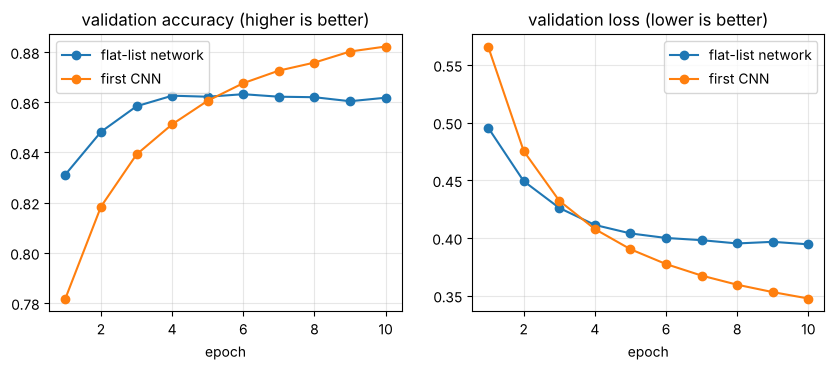

In [10]:
cnn_history = cnn.fit(x_train, y_train, epochs=EPOCHS, batch_size=64,
                      validation_data=(x_val, y_val), verbose=0).history
print("validation accuracy per epoch:", [round(a, 3) for a in cnn_history["val_accuracy"]])

fig = fashion.plot_history([dense_history, cnn_history], ["flat-list network", "first CNN"])
save_figure(fig, "01_curves.png")
plt.show()

**What to notice.** The flat-list network starts faster but flattens out; the CNN starts slower, keeps improving
and ends higher. A plateau in validation accuracy while the training accuracy keeps rising is the typical sign
of *memorising* instead of *learning*.

*Figure: validation accuracy (left) and validation loss (right) after every epoch, for both networks.*

## 6 · The final grade (test set, used once)

Only now do we open the locked test set, once per model.

In [11]:
test_results = {}
for name, model in [("flat-list network", dense), ("first CNN", cnn)]:
    loss, accuracy = model.evaluate(x_test, y_test, verbose=0)
    test_results[name] = accuracy
    print(f"{name:18s} test accuracy: {accuracy:.4f}   ({model.count_params():,} parameters)")

flat-list network  test accuracy: 0.8452   (50,890 parameters)


first CNN          test accuracy: 0.8670   (12,810 parameters)


**What to notice.** The test accuracy is the honest number we report. (Chance level, i.e. guessing, would be 10%.)
Both models are far above chance; the CNN is ahead with a quarter of the parameters. These numbers come from one training run
with one seed, so a difference of a few tenths of a percent should not be over-interpreted;
a difference of a couple of percent, as here, is more convincing but still comes from a single run.

Now look at what the CNN gets right and, more interesting, what it gets wrong.

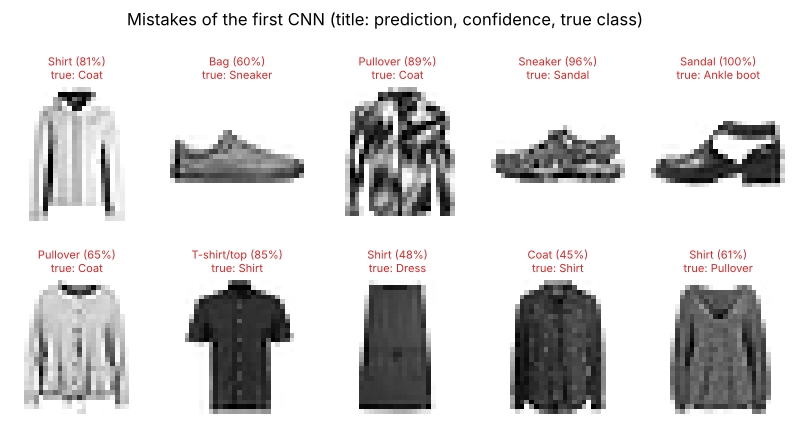

In [12]:
probabilities = cnn.predict(x_test, verbose=0)
fig = fashion.plot_predictions(x_test, y_test, probabilities, wrong=True)
fig.suptitle("Mistakes of the first CNN (title: prediction, confidence, true class)", y=1.02)
save_figure(fig, "01_mistakes.png")
plt.show()

**What to notice.** In these first ten mistakes, six are mix-ups inside the group we worried about at the beginning
(shirt, T-shirt, pullover, coat); the others are a sandal/sneaker/boot mix-up, a sneaker called a bag and a dress called a shirt.
Some of these are hard even for a person at 28 × 28 pixels. Notebook 02 measures this exactly with a confusion matrix.

*Figure: ten test pictures the CNN got wrong, with its guess, its confidence and the true class.*

## 7 · Common mistakes

- **Forgetting to scale pixels to 0–1.** Raw 0–255 numbers make training slow and unstable.
- **Using the test set to choose settings.** Then the test score is no longer honest. Use the validation set for choices.
- **Believing a single number.** One run, one seed, one accuracy: repeat with other seeds before claiming "A beats B" (we do this in notebook 02).
- **Wrong input shape.** A CNN expects `(height, width, channels)`; a grey image needs the extra channel dimension of size 1.

## 8 · Recap

- A picture is a grid of numbers; a network never "sees" anything else.
- A convolution slides a small learned kernel over the picture and asks the same question everywhere; pooling keeps the strongest answers and shrinks the map.
- Our first CNN beats a flat-list network with fewer parameters, and its mistakes are the ones a person would find hard too.

**Next:** notebook 02 makes the CNN more robust with *data augmentation*, draws honest learning curves and
looks at the errors with a confusion matrix.